# 36. Augmentation and skeleton input under the class balanced sampler (paper protocol)

The single player baselines (all four models) were trained with the **class balanced sampler** (`target_per_class` from `configs/stgcn_recipe.json`, 300 in the tuned recipe; 500 was the `dataset.py` default and the pre tuning baseline). Notebooks 32 and 33 used natural class frequencies. This notebook runs the two player work under the **same sampler protocol as the baselines**, so every number in the paper's main tables shares one protocol.

Requires the patched `two_player/two_person.py` (`build_loaders(..., target_per_class=...)`). All arms use the same base recipe, so comparisons are equal. `both_slow` is a sensitivity row: a small validation search for `both` (notebook 33, natural frequencies) preferred a slower schedule, so it is run here under the sampler to show whether that matters.

| condition | skeleton(s) | augmentation |
|---|---|---|
| both / none, basic, advanced | both players | none, basic, advanced |
| near / advanced | near player | advanced |
| old_pick / none, basic, advanced | old single skeleton | none, basic, advanced |
| both_slow / advanced | both players, learning rate step 15 and gamma 0.3 instead of 10 and 0.1 | advanced (sensitivity row, see below) |

`old_pick / none` and `old_pick / advanced` replicate the baseline CSV through this code path (a consistency check); `old_pick / basic` adds the basic policy to the single player pipeline. Test set, seeds 42, 123, 7, checkpoint chosen on the validation composite, test evaluated once per run. 24 runs in total (8 conditions, 3 seeds); `RUN_CONDITIONS` sets which are run now.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
for p in (REPO, f"{REPO}/two_player"):
    sys.path.insert(0, p)
import dataset as ds
import training as tr
import two_person as tp

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/two_player_sampler"
OLD_KP = f"{DATA}/keypoints_interp"
SEL_INTERP = f"{DATA}/keypoints_sel_interp"
OUT = f"{OUTPUTS}/experiments/two_player_sampler"
os.makedirs(OUT, exist_ok=True)

REPORT_SEEDS = [42, 123, 7]
SELECT_METRIC = "composite"
NORMALISATION, USE_COURT = "body", True
NUM_WORKERS, EVAL_WORKERS = 20, 8
FAR_COVERAGE_MIN = 0.5
DRILL_PATTERN = r"2023"
RARE_THRESHOLD = 150
N_BOOT = 2000

ARM_CFG = {"old_pick": dict(root=OLD_KP, persons=(0,)), "near": dict(root=SEL_INTERP, persons=(0,)),
           "both": dict(root=SEL_INTERP, persons=(0, 1)),
           # sensitivity row: the schedule that won the small natural frequency search in notebook 33 (step 15, gamma 0.3)
           "both_slow": dict(root=SEL_INTERP, persons=(0, 1), recipe_override={"step_size": 15, "gamma": 0.3})}
CONDITIONS = [("both", "advanced"), ("both", "none"), ("both", "basic"), ("near", "advanced"),
              ("old_pick", "advanced"), ("old_pick", "none"), ("old_pick", "basic"), ("both_slow", "advanced")]

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
TARGET = RECIPE["target_per_class"]
print("class balanced sampler target_per_class =", TARGET)
RECIPE_BOTH = dict(RECIPE)
tuned_path = f"{REPO}/configs/two_player_tuned.json"
if os.path.exists(tuned_path):
    print("note: configs/two_player_tuned.json exists (natural frequency tuning); this notebook uses the base recipe for all arms")
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]

class balanced sampler target_per_class = 300
note: configs/two_player_tuned.json exists (natural frequency tuning); this notebook uses the base recipe for all arms


In [3]:
clean_log = pd.read_csv(f"{DATA}/keypoints_sel_interp_log.csv").set_index("filepath")
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
manifest = manifest[manifest["filepath"].isin(clean_log.index)].reset_index(drop=True)
manifest = manifest[clean_log.loc[manifest["filepath"], "near_cov"].to_numpy() > 0].reset_index(drop=True)
manifest["far_found"] = clean_log.loc[manifest["filepath"], "far_cov"].to_numpy() >= FAR_COVERAGE_MIN
manifest["drill"] = manifest["filepath"].str.contains(DRILL_PATTERN)
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
IN_CH = tp.n_channels(USE_COURT)
train_counts = manifest[manifest["split"] == "train"]["class_name"].value_counts().reindex(class_names)
rare_names = [c for c in class_names if train_counts[c] < RARE_THRESHOLD]
print(manifest["split"].value_counts().to_dict(), f"| {K} classes | {len(rare_names)} limited sample classes (under {RARE_THRESHOLD} train clips)")

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
{'train': 6247, 'test': 782, 'val': 781} | 18 classes | 8 limited sample classes (under 150 train clips)


## Smoke test

Run this cell alone first.

In [4]:
tr.seed_everything(0)
rows = []
for arm, cfg in ARM_CFG.items():
    loaders = tp.build_loaders(manifest, cfg["root"], class_to_id, cfg["persons"], "basic", seed=0, batch_size=RECIPE["batch_size"],
                               num_workers=2, eval_workers=2, splits=("train", "val", "test"), target_per_class=TARGET)
    n_epoch = len(loaders["train"].dataset)
    sampled = len(list(loaders["train"].sampler))
    batch = next(iter(loaders["train"]))
    assert batch["keypoints"].shape[1:] == (len(cfg["persons"]), 30, 17, 3), batch["keypoints"].shape
    model = tp.PersonsSTGCN(IN_CH, K, len(cfg["persons"])).to(device)
    logits = tp.make_forward(USE_COURT)(model, batch, device)
    assert logits.shape == (len(batch["label"]), K)
    rows.append({"arm": arm, "train clips": n_epoch, "clips drawn per epoch": sampled, "expected": TARGET * K})
    del model, loaders
print(pd.DataFrame(rows).to_string(index=False))
print("smoke test passed")

      arm  train clips  clips drawn per epoch  expected
 old_pick         6247                   7948      5400
     near         6247                   7948      5400
     both         6247                   7948      5400
both_slow         6247                   7948      5400
smoke test passed


## Training

In [5]:
def run_cond(arm, policy, seed, results_path, done, splits=("train", "val", "test")):
    if ((done["arm"] == arm) & (done["policy"] == policy) & (done["seed"] == seed)).any():
        print(f"skip {arm} {policy} seed {seed}")
        return done
    cfg = ARM_CFG[arm]
    recipe = {**RECIPE, **cfg.get("recipe_override", {})}
    run_name = f"t36_{arm}_{policy}_s{seed}"
    print(f"\n=== {run_name} ===")
    tr.seed_everything(seed)
    task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                     tags=["two_player", "sampler_protocol", arm, policy, f"seed{seed}"], reuse_last_task_id=False,
                     auto_connect_frameworks={"matplotlib": False, "pytorch": False})
    task.connect({**recipe, "arm": arm, "policy": policy, "persons": list(cfg["persons"]), "seed": seed, "select_metric": SELECT_METRIC,
                  "balanced": True, "target_per_class": TARGET, "n_clips": len(manifest), "evaluated_splits": list(splits), "split_sha256": split_hash})
    loaders = tp.build_loaders(manifest, cfg["root"], class_to_id, cfg["persons"], policy, seed=seed, batch_size=recipe["batch_size"],
                               num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS, splits=splits, target_per_class=TARGET)
    model = tp.PersonsSTGCN(IN_CH, K, len(cfg["persons"])).to(device)
    forward = tp.make_forward(USE_COURT)
    optimizer = torch.optim.SGD(model.parameters(), lr=recipe["lr"], momentum=recipe["momentum"], weight_decay=recipe["weight_decay"])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=recipe.get("step_size", 10), gamma=recipe["gamma"])
    criterion = nn.CrossEntropyLoss(label_smoothing=recipe["label_smoothing"])
    _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device, task.get_logger(),
                                            num_epochs=recipe["num_epochs"], patience=recipe.get("patience", 20),
                                            select_metric=SELECT_METRIC, splits=splits)
    metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                            out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=splits, show=False,
                            extra={"arm": arm, "policy": policy, "seed": seed})
    task.close()
    done = pd.concat([done, pd.DataFrame([metrics])], ignore_index=True)
    done.to_csv(results_path, index=False)
    del model, loaders
    torch.cuda.empty_cache()
    return done

In [6]:
RUN_CONDITIONS = CONDITIONS[3:]

res_path = f"{OUT}/results_test.csv"
done = pd.read_csv(res_path) if os.path.exists(res_path) else pd.DataFrame(columns=["arm", "policy", "seed"])
for arm, policy in RUN_CONDITIONS:
    for seed in REPORT_SEEDS:
        done = run_cond(arm, policy, seed, res_path, done)

skip near advanced seed 42
skip near advanced seed 123
skip near advanced seed 7
skip old_pick advanced seed 42
skip old_pick advanced seed 123
skip old_pick advanced seed 7
skip old_pick none seed 42
skip old_pick none seed 123
skip old_pick none seed 7
skip old_pick basic seed 42
skip old_pick basic seed 123
skip old_pick basic seed 7
skip both_slow advanced seed 42
skip both_slow advanced seed 123
skip both_slow advanced seed 7


## Results

Mean and standard deviation over the three reporting seeds, test set (points). Conditions with all seeds finished are shown.

In [7]:
rt = pd.read_csv(res_path)
COND = [c for c in CONDITIONS if ((rt["arm"] == c[0]) & (rt["policy"] == c[1])).sum() == len(REPORT_SEEDS)]
print("finished conditions:", COND)
tcols = ["test_top1", "test_top5", "test_mca", "test_macro_f1", "val_top1", "train_top1", "train_test_gap", "best_epoch"]
g = rt.groupby(["arm", "policy"])
tm, ts = g[tcols].mean().reindex(COND), g[tcols].std().reindex(COND)
tshow = tm.copy()
for c in tcols:
    if c != "best_epoch":
        tshow[c] = (100 * tm[c]).round(2).astype(str) + " +/- " + (100 * ts[c]).round(2).astype(str)
tshow["best_epoch"] = tm["best_epoch"].round(1)
print("Li et al. ST-GCN: top1 74.41, top5 93.76, MCA 61.44. Baseline CSV (old single player, sampler): none 71.95/58.65, advanced 72.29/61.21")
tshow

finished conditions: [('both', 'advanced'), ('both', 'none'), ('both', 'basic'), ('near', 'advanced'), ('old_pick', 'advanced'), ('old_pick', 'none'), ('old_pick', 'basic'), ('both_slow', 'advanced')]
Li et al. ST-GCN: top1 74.41, top5 93.76, MCA 61.44. Baseline CSV (old single player, sampler): none 71.95/58.65, advanced 72.29/61.21


test_top1       test_top5        test_mca  \
arm       policy                                                     
both      advanced   78.3 +/- 0.45  96.21 +/- 0.07  67.86 +/- 0.02   
          none      78.18 +/- 0.81  96.08 +/- 0.39   68.2 +/- 0.72   
          basic     79.11 +/- 0.77  96.21 +/- 0.15  70.06 +/- 0.75   
near      advanced  72.72 +/- 0.15  94.12 +/- 0.46  61.13 +/- 0.55   
old_pick  advanced  71.57 +/- 0.53  94.63 +/- 0.38  59.98 +/- 0.84   
          none      71.18 +/- 0.27  93.95 +/- 0.85  58.53 +/- 0.51   
          basic     71.82 +/- 1.29  94.63 +/- 0.34  60.19 +/- 1.52   
both_slow advanced  77.71 +/- 1.74  95.44 +/- 0.48  66.35 +/- 1.16   

                     test_macro_f1        val_top1      train_top1  \
arm       policy                                                     
both      advanced  69.31 +/- 0.58  80.32 +/- 0.77  92.86 +/- 7.55   
          none      68.71 +/- 0.29  79.04 +/- 0.66  91.38 +/- 7.57   
          basic     70.46 +/- 0.55   79.98 +/- 0.2  91.11 +/- 1.81   
near      advanced   63.34 +/- 0.3   74.86 +/- 0.2  95.65 +/- 1.65   
old_pick  advanced  61.38 +/- 0.77  74.86 +/- 0.73  95.34 +/- 2.01   
          none      60.63 +/- 0.78   74.95 +/- 0.3  97.56 +/- 1.54   
          basic      60.2 +/- 2.01  73.88 +/- 0.56  87.79 +/- 3.03   
both_slow advanced   67.9 +/- 2.49  80.32 +/- 1.15  95.17 +/- 7.84   

                    train_test_gap  best_epoch  
arm       policy                                
both      advanced  14.55 +/- 7.48        23.3  
          none      13.21 +/- 6.95        24.0  
          basic      12.0 +/- 1.05        30.7  
near      advanced  22.93 +/- 1.79        34.7  
old_pick  advanced  23.77 +/- 1.51        32.0  
          none      26.37 +/- 1.77        26.7  
          basic     15.97 +/- 3.21        31.0  
both_slow advanced  17.46 +/- 6.47        35.0

In [8]:
def load_preds(arm, policy):
    out = {}
    for s in REPORT_SEEDS:
        rn = f"t36_{arm}_{policy}_s{s}"
        p = pd.read_csv(f"{OUT}/{rn}/{rn}_predictions.csv")
        out[s] = p[p["split"] == "test"].sort_values("filepath").reset_index(drop=True)
    return out

P = {c: load_preds(*c) for c in COND}
files = P[COND[0]][REPORT_SEEDS[0]]["filepath"].to_numpy()
for c in COND:
    for s in REPORT_SEEDS:
        assert (P[c][s]["filepath"].to_numpy() == files).all()
y = P[COND[0]][REPORT_SEEDS[0]]["label"].map(class_to_id).to_numpy()
Y = {c: {s: P[c][s]["pred"].map(class_to_id).to_numpy() for s in REPORT_SEEDS} for c in COND}

def top1(yt, yp): return float((yt == yp).mean())
def mca(yt, yp):
    tot = np.bincount(yt, minlength=K); hit = np.bincount(yt[yt == yp], minlength=K)
    return float((hit[tot > 0] / tot[tot > 0]).mean())
def seed_mean(c, idx, fn): return float(np.mean([fn(y[idx], Y[c][s][idx]) for s in REPORT_SEEDS]))
def boot_diff(a, b, fn, n_boot=N_BOOT, seed=0):
    rng = np.random.RandomState(seed); full = np.arange(len(y))
    point = seed_mean(a, full, fn) - seed_mean(b, full, fn)
    d = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.randint(0, len(y), len(y))
        d[i] = seed_mean(a, idx, fn) - seed_mean(b, idx, fn)
    lo, hi = np.percentile(d, [2.5, 97.5])
    return point, lo, hi

PAIRS = [(("both", "advanced"), ("both", "none")), (("both", "basic"), ("both", "none")), (("both", "advanced"), ("both", "basic")),
         (("old_pick", "advanced"), ("old_pick", "none")), (("old_pick", "basic"), ("old_pick", "none")),
         (("both", "advanced"), ("old_pick", "advanced")), (("both", "none"), ("old_pick", "none")),
         (("both", "advanced"), ("near", "advanced")), (("near", "advanced"), ("old_pick", "advanced")),
         (("both_slow", "advanced"), ("both", "advanced"))]
rows = []
for a, b in PAIRS:
    if a not in COND or b not in COND:
        continue
    row = {"comparison": f"{a[0]}/{a[1]} - {b[0]}/{b[1]}"}
    for fn, label in ((top1, "top1"), (mca, "mca")):
        pt, lo, hi = boot_diff(a, b, fn)
        row[f"{label} (pts)"] = round(100 * pt, 2)
        row[f"{label} 95% CI"] = f"[{100 * lo:+.2f}, {100 * hi:+.2f}]"
    rows.append(row)
diffs = pd.DataFrame(rows)
print("paired bootstrap over test clips (does not include seed to seed variation)")
diffs

paired bootstrap over test clips (does not include seed to seed variation)


,comparison,top1 (pts),top1 95% CI,mca (pts),mca 95% CI
0,both/advanced - both/none,0.13,"[-1.02, +1.28]",-0.34,"[-2.33, +1.76]"
1,both/basic - both/none,0.94,"[-0.47, +2.30]",1.87,"[-0.15, +3.94]"
2,both/advanced - both/basic,-0.81,"[-2.22, +0.55]",-2.21,"[-4.51, +0.15]"
3,old_pick/advanced - old_pick/none,0.38,"[-1.02, +1.79]",1.45,"[-0.30, +3.24]"
4,old_pick/basic - old_pick/none,0.64,"[-1.28, +2.47]",1.66,"[-0.89, +4.33]"
5,both/advanced - old_pick/advanced,6.73,"[+4.73, +8.78]",7.88,"[+4.68, +11.16]"
6,both/none - old_pick/none,6.99,"[+4.94, +9.17]",9.67,"[+6.48, +13.12]"
7,both/advanced - near/advanced,5.58,"[+3.66, +7.50]",6.73,"[+3.58, +9.92]"
8,near/advanced - old_pick/advanced,1.15,"[-0.34, +2.64]",1.15,"[-1.58, +4.03]"
9,both_slow/advanced - both/advanced,-0.60,"[-1.88, +0.68]",-1.51,"[-3.49, +0.42]"


### Where the differences land

Recall for the limited sample classes (under 150 training clips) and the common classes; per class recall.

In [9]:
def recall_by_class(c):
    r = np.zeros((len(REPORT_SEEDS), K))
    for i, s in enumerate(REPORT_SEEDS):
        for k in range(K):
            m = y == k
            r[i, k] = (Y[c][s][m] == k).mean() if m.any() else np.nan
    return r.mean(axis=0)

lab = lambda c: f"{c[0]}/{c[1]}"
rec = pd.DataFrame({lab(c): recall_by_class(c) for c in COND}, index=[c.split("_", 1)[-1] for c in class_names])
rare_idx = [class_names.index(c) for c in rare_names]
common_idx = [k for k in range(K) if k not in rare_idx]
group = pd.DataFrame({lab(c): {"limited sample recall": rec[lab(c)].iloc[rare_idx].mean(), "common recall": rec[lab(c)].iloc[common_idx].mean()} for c in COND}).T
print("limited sample classes:", [c.split("_", 1)[-1] for c in rare_names])
display((100 * group).round(2))
per_class = (100 * rec).round(1)
per_class["support"] = np.bincount(y, minlength=K)
per_class

limited sample classes: ['Cross Court Flight', 'Tap Smash', 'Transitional Slice', 'Rush Shot', 'Defensive Clear', 'Defensive Drive', 'Rear Court Flat Drive', 'Short Flat Shot']


,limited sample recall,common recall
both/advanced,60.37,73.85
both/none,61.85,73.27
both/basic,64.76,74.31
near/advanced,51.14,69.12
old_pick/advanced,50.40,67.64
old_pick/none,46.74,67.96
old_pick/basic,52.46,66.37
both_slow/advanced,56.74,74.03


,both/advanced,both/none,both/basic,near/advanced,old_pick/advanced,old_pick/none,old_pick/basic,both_slow/advanced,support
Short Serve,97.7,97.3,97.7,96.6,97.3,97.0,97.3,98.1,88
Cross Court Flight,45.8,50.0,56.2,37.5,37.5,27.1,45.8,43.8,16
Lift,74.1,73.7,76.3,71.1,63.6,68.0,75.0,74.1,76
Tap Smash,45.5,39.4,48.5,36.4,39.4,39.4,36.4,51.5,11
Block,79.6,81.7,86.0,68.8,72.0,68.8,72.0,79.6,31
Drop Shot,89.7,88.1,86.8,79.8,77.4,77.4,73.3,89.3,81
Push Shot,32.5,31.7,27.5,36.7,35.0,29.2,24.2,40.8,40
Transitional Slice,51.3,56.4,59.0,25.6,35.9,28.2,33.3,38.5,13
Cut,78.5,71.2,75.1,68.9,66.1,65.5,57.1,76.3,59
Rush Shot,69.4,63.9,66.7,66.7,52.8,58.3,50.0,63.9,12


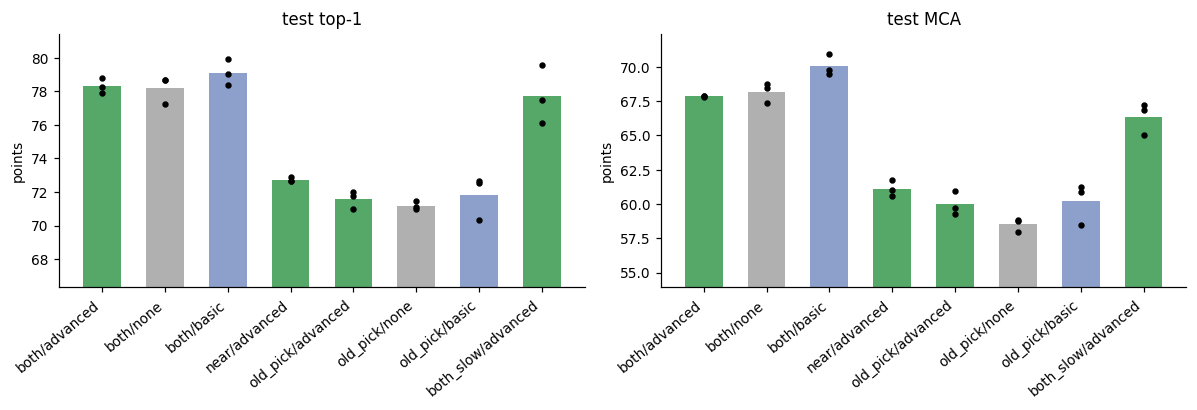

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in zip(axes, ("test_top1", "test_mca"), ("test top-1", "test MCA")):
    for j, c in enumerate(COND):
        v = 100 * rt[(rt["arm"] == c[0]) & (rt["policy"] == c[1])][col].to_numpy()
        ax.bar(j, v.mean(), color={"none": "#b0b0b0", "basic": "#8da0cb", "advanced": "#55a868"}[c[1]], width=0.6)
        ax.scatter([j] * len(v), v, color="k", s=10, zorder=3)
    ax.set_xticks(range(len(COND)), [lab(c) for c in COND], rotation=40, ha="right")
    ax.set_ylim(100 * rt[col].min() - 4, 100 * rt[col].max() + 1.5)
    ax.set_title(title); ax.set_ylabel("points")
fig.tight_layout()
plt.show()

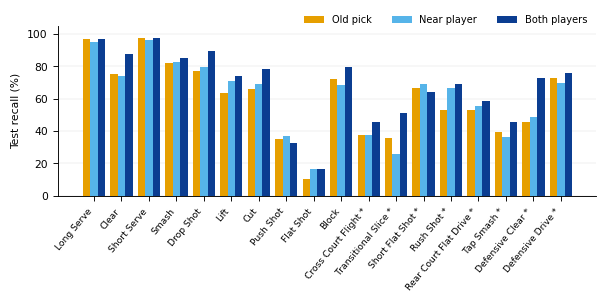

In [11]:
# Paper figure: per class test recall (old pick, near, both; advanced augmentation)
FIG_DIR = f"{REPO}/paper_figures"; os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"font.size": 7, "axes.linewidth": 0.6, "xtick.major.width": 0.6,
                     "ytick.major.width": 0.6, "axes.spines.top": False, "axes.spines.right": False})

support = np.bincount(y, minlength=K)
names = [str(n).replace("_", " ") for n in rec.index]
rare = {c.split("_", 1)[-1].replace("_", " ") for c in rare_names}
order_k = np.argsort(-support, kind="stable")                 # most test clips first
series = [("old_pick/advanced", "Old pick",     "#E69F00"),   # orange
          ("near/advanced",     "Near player",  "#56B4E9"),   # sky blue
          ("both/advanced",     "Both players", "#0B3D91")]   # dark navy

x, w = np.arange(K), 0.27
fig, ax = plt.subplots(figsize=(5.4, 2.7))
for j, (col, label, color) in enumerate(series):
    ax.bar(x + (j - 1) * w, 100 * rec[col].to_numpy()[order_k], w, color=color, label=label, lw=0)
ax.set_xticks(x)
ax.set_xticklabels([names[k] + (" *" if names[k] in rare else "") for k in order_k],
                   rotation=50, ha="right", fontsize=6)
ax.set_ylabel("Test recall (%)"); ax.set_ylim(0, 105)
ax.legend(frameon=False, ncol=3, loc="upper right", fontsize=6.5, bbox_to_anchor=(1, 1.12))
ax.grid(axis="y", lw=0.3, color="#dddddd"); ax.set_axisbelow(True)
fig.tight_layout(pad=0.4)
fig.savefig(f"{FIG_DIR}/fig_per_class_recall.png", dpi=300)
plt.show()

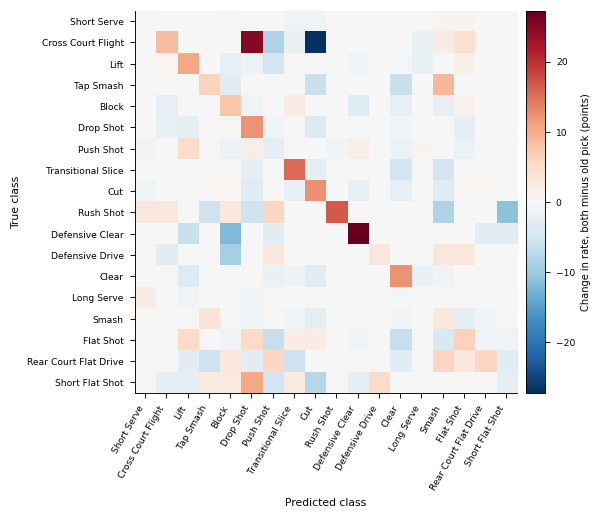

largest drops in a confusion:


,true,predicted,old pick %,both %,change
24,Cross Court Flight,Cut,27.1,0.0,-27.1
174,Defensive Clear,Block,12.1,0.0,-12.1
169,Rush Shot,Short Flat Shot,11.1,0.0,-11.1
191,Defensive Drive,Block,15.2,6.1,-9.1
22,Cross Court Flight,Push Shot,8.3,0.0,-8.3
166,Rush Shot,Smash,16.7,8.3,-8.3
297,Short Flat Shot,Cut,7.7,0.0,-7.7
267,Flat Shot,Clear,12.5,6.2,-6.2
261,Flat Shot,Push Shot,18.8,12.5,-6.2
62,Tap Smash,Clear,6.1,0.0,-6.1


largest remaining confusions with both players:


,true,predicted,old pick %,both %,change
64,Tap Smash,Smash,45.5,54.5,9.1
104,Push Shot,Lift,36.7,41.7,5.0
21,Cross Court Flight,Drop Shot,12.5,37.5,25.0
257,Flat Shot,Lift,22.9,28.1,5.2
126,Transitional Slice,Cut,25.6,23.1,-2.6
172,Defensive Clear,Lift,24.2,18.2,-6.1
263,Flat Shot,Cut,14.6,16.7,2.1
123,Transitional Slice,Block,15.4,15.4,0.0
294,Short Flat Shot,Drop Shot,5.1,15.4,10.3
261,Flat Shot,Push Shot,18.8,12.5,-6.2


In [12]:
# Where the second player helps: change in row-normalised confusion, old pick -> both (advanced)
names = [str(n).replace("_", " ") for n in rec.index]

def conf_rate(c):
    M = np.zeros((K, K))
    for s in REPORT_SEEDS:
        np.add.at(M, (y, Y[c][s]), 1)
    return M / M.sum(axis=1, keepdims=True)

A, B = conf_rate(("old_pick", "advanced")), conf_rate(("both", "advanced"))
D = 100 * (B - A)

fig, ax = plt.subplots(figsize=(5.4, 4.6))
lim = np.abs(D).max()
im = ax.imshow(D, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_xticks(range(K)); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=6)
ax.set_yticks(range(K)); ax.set_yticklabels(names, fontsize=6)
ax.set_xlabel("Predicted class", fontsize=7); ax.set_ylabel("True class", fontsize=7)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02); cb.ax.tick_params(labelsize=6)
cb.set_label("Change in rate, both minus old pick (points)", fontsize=6.5)
fig.tight_layout(pad=0.4)
fig.savefig(f"{REPO}/paper_figures/fig_confusion_change.png", dpi=300)
plt.show()

rows = []
for t in range(K):
    for p in range(K):
        if t != p:
            rows.append((names[t], names[p], 100*A[t, p], 100*B[t, p], 100*(B[t, p]-A[t, p])))
cf = pd.DataFrame(rows, columns=["true", "predicted", "old pick %", "both %", "change"])
print("largest drops in a confusion:"); display(cf.sort_values("change").head(10).round(1))
print("largest remaining confusions with both players:"); display(cf.sort_values("both %", ascending=False).head(10).round(1))

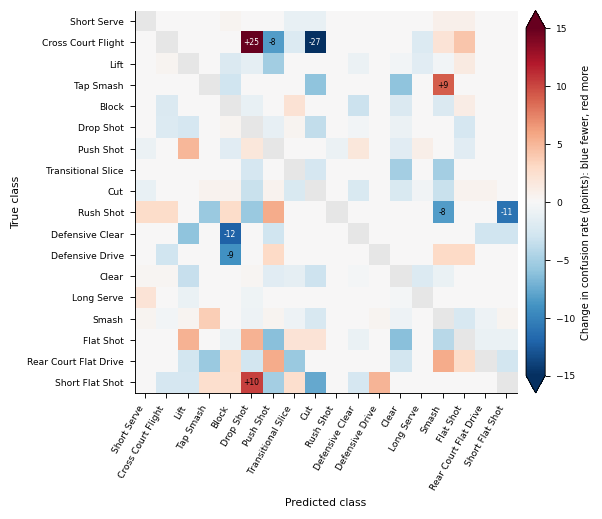

In [13]:
# Where the second player helps: change in off-diagonal confusion rates, old pick -> both (advanced)
names = [str(n).replace("_", " ") for n in rec.index]

def conf_rate(c):
    M = np.zeros((K, K))
    for s in REPORT_SEEDS:
        np.add.at(M, (y, Y[c][s]), 1)
    return M / M.sum(axis=1, keepdims=True)

A, B = conf_rate(("old_pick", "advanced")), conf_rate(("both", "advanced"))
D = 100 * (B - A)
np.fill_diagonal(D, np.nan)                      # recall is shown in the per class figure

cmap = plt.get_cmap("RdBu_r").copy(); cmap.set_bad("#e6e6e6")
LIM = 15
fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(np.ma.masked_invalid(D), cmap=cmap, vmin=-LIM, vmax=LIM)
ax.set_xticks(range(K)); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=6)
ax.set_yticks(range(K)); ax.set_yticklabels(names, fontsize=6)
ax.set_xlabel("Predicted class", fontsize=7); ax.set_ylabel("True class", fontsize=7)
for t in range(K):
    for p in range(K):
        if t != p and abs(D[t, p]) >= 8:
            ax.text(p, t, f"{D[t, p]:+.0f}", ha="center", va="center", fontsize=5,
                    color="white" if abs(D[t, p]) > 11 else "black")
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02, extend="both"); cb.ax.tick_params(labelsize=6)
cb.set_label("Change in confusion rate (points): blue fewer, red more", fontsize=6.5)
fig.tight_layout(pad=0.4)
fig.savefig(f"{REPO}/paper_figures/fig_confusion_change.png", dpi=300)
plt.show()

In [15]:
cols = ["arm","policy","seed","test_top1","test_top5","test_mca","test_macro_f1"]
print(rt[cols].sort_values(["arm","policy","seed"]).round(2).to_string(index=False))
m = tp.PersonsSTGCN(IN_CH, K, 2); s = tp.PersonsSTGCN(IN_CH, K, 1)
print(sum(p.numel() for p in m.parameters()), sum(p.numel() for p in s.parameters()))

      arm   policy  seed  test_top1  test_top5  test_mca  test_macro_f1
     both advanced     7       0.79       0.96      0.68           0.70
     both advanced    42       0.78       0.96      0.68           0.69
     both advanced   123       0.78       0.96      0.68           0.69
     both    basic     7       0.80       0.96      0.70           0.71
     both    basic    42       0.79       0.96      0.69           0.70
     both    basic   123       0.78       0.96      0.71           0.70
     both     none     7       0.77       0.96      0.69           0.68
     both     none    42       0.79       0.96      0.67           0.69
     both     none   123       0.79       0.96      0.68           0.69
both_slow advanced     7       0.80       0.96      0.67           0.70
both_slow advanced    42       0.77       0.95      0.67           0.68
both_slow advanced   123       0.76       0.96      0.65           0.65
     near advanced     7       0.73       0.94      0.61        

In [17]:
v = pd.read_csv(f"{OUTPUTS}/results/wrong_player_audit_verdicts.csv")
auto = pd.read_csv(f"{OUTPUTS}/results/old_pick_vs_selection.csv").set_index("filepath")
v["split"] = auto.loc[v["filepath"], "split"].to_numpy()
print(pd.crosstab(v["actor"], v["old_is"], margins=True)); print(v["split"].value_counts())
a = json.load(open(f"{OUTPUTS}/results/wrong_player_audit.json")); print(a["wrong_rate"], a["wrong_ci95"])

old_is   near  neither  All
actor                      
far        33        0   33
near       24        0   24
unclear     0        3    3
All        57        3   60
split
train    47
test      8
val       5
Name: count, dtype: int64
0.5789473684210527 [0.4497991014068138, 0.6981260024694814]


In [19]:
logs = [f"{DATA}/{n}" for n in sorted(os.listdir(DATA)) if n.startswith("extraction_sel_log")]
sel = pd.concat([pd.read_csv(f) for f in logs]).drop_duplicates("filepath").set_index("filepath")
miss = (sel["n_persons"].reindex(files) != 2).to_numpy()
clean = pd.read_csv(f"{DATA}/keypoints_sel_interp_log.csv").set_index("filepath")
miss2 = (clean["far_cov"].reindex(files) < 0.5).to_numpy()
def sl(c, m): return round(100*np.mean([top1(y[m], Y[c][s][m]) for s in REPORT_SEEDS]), 1)
for name, m in [("n_persons != 2 (the paper's 187)", miss), ("far_cov < 0.5", miss2)]:
    print(name, "test clips:", int(m.sum()), "of", len(m))
    for c in [("both","advanced"), ("near","advanced"), ("old_pick","advanced")]:
        print("  ", c, "missing:", sl(c, m), "present:", sl(c, ~m))
print((sel["n_persons"].reindex(manifest["filepath"]).ne(2)).groupby(manifest["split"].to_numpy()).sum())

n_persons != 2 (the paper's 187) test clips: 15 of 782
   ('both', 'advanced') missing: 68.9 present: 78.5
   ('near', 'advanced') missing: 64.4 present: 72.9
   ('old_pick', 'advanced') missing: 66.7 present: 71.7
far_cov < 0.5 test clips: 15 of 782
   ('both', 'advanced') missing: 68.9 present: 78.5
   ('near', 'advanced') missing: 64.4 present: 72.9
   ('old_pick', 'advanced') missing: 66.7 present: 71.7
test      15
train    157
val       15
Name: n_persons, dtype: int64


In [16]:
assert len(COND) == len(CONDITIONS), f"run all conditions before saving the summary (done: {COND})"
summary = {"experiment": "two_player_sampler_protocol", "report_seeds": REPORT_SEEDS, "target_per_class": TARGET, "n_clips": int(len(manifest)),
           "test_mean": {lab(c): {k: float(tm.loc[c, k]) for k in tcols} for c in COND},
           "test_differences": diffs.to_dict(orient="records"),
           "group_recall": {k: {kk: float(vv) for kk, vv in v.items()} for k, v in group.to_dict(orient="index").items()}}
os.makedirs(f"{REPO}/configs", exist_ok=True)
with open(f"{REPO}/configs/two_player_sampler.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
task = Task.init(project_name=PROJECT, task_name="two_player_sampler_summary", task_type=Task.TaskTypes.qc,
                 tags=["two_player", "sampler_protocol", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
log = task.get_logger()
task.connect({**RECIPE, "report_seeds": REPORT_SEEDS, "split_sha256": split_hash})
log.report_table("summary", "test", iteration=0, table_plot=tshow.reset_index())
log.report_table("differences", "test", iteration=0, table_plot=diffs)
log.report_table("per class recall", "test", iteration=0, table_plot=per_class.reset_index())
log.report_matplotlib_figure("top1 and MCA", "test", figure=fig, iteration=0, report_interactive=False)
task.upload_artifact("summary", artifact_object=f"{REPO}/configs/two_player_sampler.json")
task.close()
print("saved configs/two_player_sampler.json")

ClearML Task: created new task id=5ef8819896154d6bba197fdf4a98dfe1
2026-10-10 15:39:18,686 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/80231b1d7b164b96ad0b281dfa1309a3/tasks/5ef8819896154d6bba197fdf4a98dfe1/output/log
saved configs/two_player_sampler.json
